# Coding Session 10: Can we trust a turnout score? — Solutions

A **turnout model** predicts each registered voter's probability of voting in an election. That probability is their **propensity**. A score of 0.80 means an 80% predicted chance of voting, not a promise that the person will vote.

We will load real North Carolina records, fit a simple model, and check its predictions. Each step introduces an idea, demonstrates it in code, and interprets the result. Examples labeled **hypothetical** use made-up numbers.

## 1. Understand the records we will model

The file contains **47,463 people** retained from a random sample of 50,000 adults registered in North Carolina at the start of 2024. The other **2,537** sampled records could not be linked reliably and were excluded, not counted as nonvoters. The file includes people with no recorded voting history. The [data notes](https://github.com/albertostefanelli/DSPC_coding_sessions/blob/codex/wk10-turnout-data/wk10_turnout_models/data/README.md) document preparation and exclusions.

Each row is one person. We predict recorded participation in the **2024 presidential election**, using information from earlier elections and the registration snapshot.

| Column | Meaning |
|---|---|
| `row_id` | An arbitrary teaching row number; not a public voter identifier. |
| `age_2024` | Age recorded in the January 2024 registration snapshot. |
| `registration_year` | Recorded registration year; not necessarily the first year someone could vote. |
| `voted_2018`, `voted_2020`, `voted_2022` | 1 if participation is recorded in that general election; 0 if none is recorded. |
| `voted_2024` | The outcome: recorded participation in the 2024 general election, coded the same way. |

**Interpret the population carefully.** These are records for the selected January registrants whose identifiers could be checked, not all eligible North Carolinians or everyone who registered later in 2024. A 0 means no participation recorded in this file. It could reflect nonvoting, youth, later registration, or voting outside these records. A row of zeros does not prove that someone is a habitual nonvoter. People absent from the registration file cannot receive a score from it. The prepared file contains no names or contact details.

In Colab, save your own copy first. The data load directly from the internet; there is nothing to upload. Run the cells in order.

In [1]:
# pandas works with tables; statsmodels fits the regression.
import pandas as pd
import statsmodels.formula.api as smf

# Load a fixed teaching extract. This address needs an internet connection.
# Python reads the CSV into a table called vf (voter file).
vf = pd.read_csv('https://raw.githubusercontent.com/albertostefanelli/DSPC_coding_sessions/0346cd0991e445edcbd7f7a10cba2194186961d6/wk10_turnout_models/data/nc_turnout_2024_teaching.csv')

print('People:', len(vf))
print('Missing values in each column:')
print(vf.isna().sum())
vf.head()

People: 47463
Missing values in each column:
row_id                0
age_2024              0
registration_year    25
voted_2018            0
voted_2020            0
voted_2022            0
voted_2024            0
dtype: int64


,row_id,age_2024,registration_year,voted_2018,voted_2020,voted_2022,voted_2024
0,1,30,2020.0,1,1,0,0
1,2,23,2020.0,0,0,0,0
2,3,21,2023.0,0,0,0,0
3,4,56,2022.0,0,0,1,1
4,5,52,1997.0,0,1,0,1


The model's predictors and outcome are complete. **25 registration years** are unavailable after checking the administrative dates. We retain those people: registration year is descriptive and is not a predictor in our regression.

## 2. Fit a model, keeping an honest test

### 2a. Hold some voters back

**Overfitting** means fitting the people used to build a model so closely that it predicts new people poorly. Testing on those same people can give an overly reassuring result.

We will randomly use 70% of voters to **train** the model and hold back 30% to **test** it. The held-out outcomes will play no part in estimating the coefficients. This checks other voters in this sample and election; it does not establish performance elsewhere or in a future election.

In [2]:
# Select 70% of rows at random for fitting.
# random_state fixes the draw so everyone uses the same split.
train = vf.sample(frac=0.7, random_state=10)

# The remaining rows are the test voters. copy() lets us add prediction columns.
test = vf.drop(train.index).copy()
print(len(train), 'training voters;', len(test), 'held-out voters')

# Check that no row appears in both groups.
assert train.index.intersection(test.index).empty

33224 training voters; 14239 held-out voters


We have **33,224 training voters** and **14,239 held-out voters**, with no overlap. Only the training rows go into the regression.

### 2b. Turn past voting into a score

Start with a past election where we know who voted. The **outcome** is 1 for a recorded vote and 0 otherwise. The **predictors** describe what was known beforehand: earlier voting history and age. The regression will find this pattern using only the training voters. In the formula below, the 2024 outcome goes on the left; the earlier predictors go on the right.

A **linear probability model** is a linear regression with a 0/1 outcome. Its prediction adds a starting value (the **intercept**) to each predictor multiplied by its coefficient. Multiply a coefficient by 100 to express the difference in **percentage points**, holding the other predictors fixed.

> **Hypothetical example.** Suppose the score is 0.20 + 0.15 × voted in 2018 + 0.25 × voted in 2020 + 0.20 × voted in 2022 + 0.001 × age. Someone aged 40 who skipped 2018 but voted in 2020 and 2022 scores 0.20 + 0 + 0.25 + 0.20 + 0.04 = **0.69**. The 2020 coefficient is a 25-point prediction difference between otherwise identical profiles; it is not the effect of making someone vote in 2020.

![An additive score calculation for a fictional voter, ending at 69 percent.](https://raw.githubusercontent.com/albertostefanelli/DSPC_coding_sessions/0346cd0991e445edcbd7f7a10cba2194186961d6/wk10_turnout_models/assets/previews/fig1_additive_turnout_score.png)

*Figure 1. Hypothetical coefficients add up to a turnout score.*

In [3]:
# The outcome is 2024 participation. Every predictor refers to earlier information.
# ols fits a straight line; .fit() estimates the coefficients on training voters only.
model = smf.ols(
    'voted_2024 ~ voted_2018 + voted_2020 + voted_2022 + age_2024',
    data=train
).fit()

# Convert coefficients from proportions to percentage points.
# The intercept is the starting value, not the sample's average turnout.
print('Coefficients in percentage points:')
print((100 * model.params).round(2))

Coefficients in percentage points:
Intercept     45.74
voted_2018     1.88
voted_2020    17.40
voted_2022    32.07
age_2024      -0.03
dtype: float64


Holding the other predictors fixed, a recorded 2020 vote is associated with a **+17.4-point** prediction difference. Ten additional years of age correspond to **-0.3 points**. The age coefficient compares people with the same included voting history; it does not describe how turnout varies with age overall. These are predictive associations, not causal effects. The intercept is a mathematical starting point for an age-zero profile with no earlier votes, not a useful voter description.

### 2c. Predict the held-out voters

`predict()` applies the fitted equation to each test row. A linear prediction can fall below 0 or above 1, so we **trim** it to the 0–1 range. Trimming keeps a score within the probability range; it does not make it accurate.

To make a yes/no call, predict **“will vote” at 0.50 or above** and **“will not vote” below 0.50**. Keep both the probability score and the call: they answer different questions.

In [4]:
# Predictions retain the test rows' indexes, so each score stays beside its outcome.
test['raw_score'] = model.predict(test)

# Linear predictions can leave the probability range. Trim to 0–1.
test['score'] = test['raw_score'].clip(0, 1)
outside = (test['raw_score'] < 0) | (test['raw_score'] > 1)
print('Raw score range:', round(test['raw_score'].min(), 3),
      'to', round(test['raw_score'].max(), 3))
print('Scores trimmed:', outside.sum(), 'of', len(test))

# astype(int) turns True/False into 1/0 for comparison with the outcome.
test['predicted_vote'] = (test['score'] >= 0.5).astype(int)
test[['voted_2024', 'raw_score', 'score', 'predicted_vote']].head()

Raw score range: 0.433 to 0.965
Scores trimmed: 0 of 14239


,voted_2024,raw_score,score,predicted_vote
2,0,0.452110,0.452110,0
3,1,0.763945,0.763945,1
4,1,0.618320,0.618320,1
6,1,0.621353,0.621353,1
10,0,0.442253,0.442253,0


Trimming changes **0** of the **14,239** test scores. A score of exactly 1 still does not guarantee a vote: it may be a trimmed linear prediction. We must compare the predictions with outcomes before judging their usefulness.

## 3. Does the model beat the “free answer”?

**Accuracy** is the share of yes/no predictions that are correct. A high number can be easy to achieve when most people have the same outcome.

The **free answer** is the accuracy we get by **predicting the more common outcome for everyone**. It is “free” because this rule uses no individual age or voting history and needs no fitted regression.

> **Hypothetical example:** Of 100 people, 80 vote and 20 do not. Predicting “will vote” for all 100 gets **80 right**, so its accuracy is **80%**. Predicting “will not vote” for all 100 gets only **20 right**. The free answer is the better of these two rules: **80%**. A model getting 83 right adds **3 percentage points** beyond that benchmark.

If only 35 of 100 people vote, predicting “will not vote” for everyone gets 65 right: the free answer is then **65%**. In general, take the larger of the **turnout rate** and the **nonvoting rate**.

The **0.50 cutoff** above turns an individual's score into a call. The **free answer** measures how often the same call for everyone would be correct. Having two possible outcomes does not make 50% the appropriate accuracy benchmark.

Below, compare both rules and our model on the **same held-out voters**. We use their observed outcomes to evaluate accuracy after the election; those outcomes were not used to fit the regression.

In [5]:
actual = test['voted_2024']
predicted = test['predicted_vote']

# A correct call gives True (1); a wrong call gives False (0).
# Their mean is the share of predictions that are correct.
accuracy = (predicted == actual).mean()

# Everyone-votes is right whenever the outcome is 1.
# Nobody-votes is right whenever the outcome is 0.
turnout_rate = actual.mean()
nonvoting_rate = 1 - turnout_rate

# max() chooses the better of the two same-answer-for-everyone rules.
free_answer = max(turnout_rate, nonvoting_rate)
print('Everyone-votes accuracy (%):', round(100 * turnout_rate, 1))
print('Nobody-votes accuracy (%):', round(100 * nonvoting_rate, 1))
print('Free-answer accuracy (%):', round(100 * free_answer, 1))
print('Model accuracy (%):', round(100 * accuracy, 1))

# Subtract the proportions first, then convert to percentage points.
print('Improvement (pp):', round(100 * (accuracy - free_answer), 1))

Everyone-votes accuracy (%): 75.4
Nobody-votes accuracy (%): 24.6
Free-answer accuracy (%): 75.4
Model accuracy (%): 78.2
Improvement (pp): 2.7


Predicting “will vote” for everyone gets **75.4%** right here, without using anyone's age or voting history. Our model gets **78.2%** right: an improvement of **2.7 percentage points**, calculated before rounding. That is roughly three more correct calls per 100 people.

The model improves on the simple rule, but most of its headline accuracy was already available from the high turnout rate. We still need to inspect its mistakes and check whether its probability scores match turnout. Extra correct predictions are not extra votes caused by a campaign.

## 4. Which mistakes did it make?

A **confusion matrix** separates the four combinations of prediction and outcome. “Positive” means the model called someone a voter; “true” means it was right.

| | Actually voted | Did not vote |
|---|---|---|
| Model said “will vote” | True positive (TP) | False positive (FP) |
| Model said “will not vote” | False negative (FN) | True negative (TN) |

- **Precision = TP ÷ (TP + FP):** among the people it called voters, how many voted?
- **Recall = TP ÷ (TP + FN):** among the people who voted, how many did it identify?

Calling everyone a voter gives 100% recall, even if many calls are wrong. Two models can have the same accuracy but make different mistakes. If a program skips everyone predicted to vote, false positives mean skipping people who stay home: precision draws attention to those mistakes. If it sends persuasion mail to predicted voters, false negatives mean missing people who do vote: recall draws attention to those mistakes. Neither metric tells us whether contact would change anyone's behavior.

![Two confusion matrices with 70 percent accuracy but different precision and recall.](https://raw.githubusercontent.com/albertostefanelli/DSPC_coding_sessions/0346cd0991e445edcbd7f7a10cba2194186961d6/wk10_turnout_models/assets/previews/fig2_same_accuracy_different_mistakes.png)

*Figure 2. The same accuracy can hide different kinds of error. All counts are hypothetical.*

In the code, `&` means both statements must be true; `.sum()` counts the rows where that happens.

In [6]:
# Each row belongs in exactly one of the four boxes.
tp = ((predicted == 1) & (actual == 1)).sum()  # called a voter, and voted
fp = ((predicted == 1) & (actual == 0)).sum()  # called a voter, but did not vote
fn = ((predicted == 0) & (actual == 1)).sum()  # called a nonvoter, but voted
tn = ((predicted == 0) & (actual == 0)).sum()  # called a nonvoter, and did not vote

confusion = pd.DataFrame(
    [[tp, fp], [fn, tn]],
    index=['Model said will vote', 'Model said will not vote'],
    columns=['Actually voted', 'Did not vote']
)
print(confusion)
assert tp + fp + fn + tn == len(test)

precision = tp / (tp + fp)
recall = tp / (tp + fn)
print('Precision (%):', round(100 * precision, 1))
print('Recall (%):', round(100 * recall, 1))

                          Actually voted  Did not vote
Model said will vote                9475          1837
Model said will not vote            1268          1659
Precision (%): 83.8
Recall (%): 88.2


Among people called voters, **83.8%** have a recorded vote: this is precision. The model identifies **88.2%** of the people with recorded votes: this is recall.

The **1,837 false positives** were called voters but have no recorded vote; the **1,268 false negatives** have a recorded vote but were called nonvoters. These are different mistakes that one overall accuracy number hides. Neither count measures how many votes a contact program could add.

## 5. Do the probabilities mean what they say?

A model is **calibrated** when, among people scored around 0.60, about 60% vote. Accuracy, precision, and recall use yes/no calls; calibration checks the probability scores themselves.

Group people into score ranges, such as 0.50–0.60. For each group, compare its **average score** with the **share who actually voted**. On a calibration chart, the average score goes across and observed turnout goes up. Perfect agreement lies on the diagonal. Below the line means overprediction; above it means underprediction. Put each dot at the group's average score, not at the midpoint of its range.

> **Hypothetical example.** A group averages 0.60 but only 40% vote. The model overpredicts turnout by **20 percentage points**. It could still classify many individuals correctly at a 0.50 cutoff.

Always show the number of people in each group. A small group gives a less stable comparison. Agreement overall can still hide errors within particular groups.

![A calibration diagram showing agreement on the diagonal and overprediction below it.](https://raw.githubusercontent.com/albertostefanelli/DSPC_coding_sessions/0346cd0991e445edcbd7f7a10cba2194186961d6/wk10_turnout_models/assets/previews/fig3_what_calibration_means.png)

*Figure 3. A calibration check compares a group’s mean score with its turnout. Hypothetical illustration.*

The code groups scores into ranges and reports their mean scores, turnout rates, and sizes. A **positive gap means overprediction**.

In [7]:
# Put scores into ten ranges. include_lowest=True keeps exact zeros.
# Each range includes its upper edge, so exact ones are counted too.
ranges = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1]
test['score_range'] = pd.cut(test['score'], ranges, include_lowest=True)

# groupby splits people by score range; mean() averages each selected column.
# observed=True omits empty ranges. These are group MEANS, not range midpoints.
calibration = test.groupby('score_range', observed=True)[['score', 'voted_2024']].mean()
# size() counts the people in each range.
calibration['people'] = test.groupby('score_range', observed=True).size()
calibration['gap_pp'] = 100 * (calibration['score'] - calibration['voted_2024'])

# Every held-out person must appear in one range.
assert calibration['people'].sum() == len(test)
calibration[['people', 'score', 'voted_2024', 'gap_pp']].round(3)

,people,score,voted_2024,gap_pp
score_range,,,,
"(0.4, 0.5]",2927,0.450,0.433,1.634
"(0.6, 0.7]",3800,0.627,0.635,-0.876
"(0.7, 0.8]",632,0.768,0.869,-10.057
"(0.9, 1.0]",6880,0.952,0.947,0.580


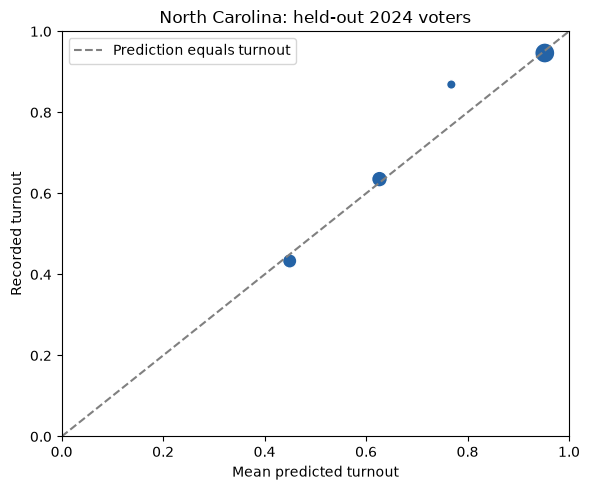

In [8]:
import matplotlib.pyplot as plt

# Each dot is a score range. Bigger dots represent more people.
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], '--', color='gray', label='Prediction equals turnout')
ax.scatter(calibration['score'], calibration['voted_2024'],
           s=30 + 180 * calibration['people'] / calibration['people'].max(),
           color='#2463a6', edgecolor='white')
ax.set(xlabel='Mean predicted turnout', ylabel='Recorded turnout',
       xlim=(0, 1), ylim=(0, 1), title='North Carolina: held-out 2024 voters')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

One populated range contains **632 people** with an average score of **76.8%**, while **86.9%** have a recorded vote. The model **underpredicts** by **10.1 points** there. Read the group sizes alongside the gaps; a handful of people cannot support the same confidence as a large group. Trimming scores did not guarantee calibration.

### What these checks let us conclude

**Match the election.** Presidential and midterm elections have different turnout patterns. A model fitted to a presidential election should not automatically become a midterm model. Applying a past pattern to a future election assumes that the relationship remains useful; we cannot verify that future score until we observe the outcome.

**Separate turnout, support, and response.** A turnout score predicts participation. A **support score** predicts support for a candidate and needs information such as survey answers; party registration is not the same thing as candidate support. The **treatment effect** of contact is how much contact changes turnout. Neither a high score nor a score near 0.50 establishes a large treatment effect. To estimate it, randomly assign people to contact or no contact and compare their turnout.

Our historical records include whatever campaigning actually occurred. We can use a turnout prediction as a proposed baseline for planning an additional contact, but these records do not identify what would happen in an election with no campaigning.

## 6. Three short exercises

Each exercise needs a few lines of code and **two or three sentences of interpretation**. Explain the meaning of the result, quote the relevant numbers, and name any assumption your conclusion needs. Use percentages for turnout levels and percentage points for differences.

The claims and fictional profiles are hypothetical. Exercises 1 and 3 use the model fitted to the real records; Exercise 2 uses a small hypothetical dataset. The exercise code cells contain comments only. Write your calculations there, then fill in the interpretation cell.

### Exercise 1: What changes a predicted score?

These **fictional profiles** are both age 40 in the snapshot and have no recorded vote in 2018 or 2022. They differ only in recorded participation in 2020.

**Coding guide.** `model.predict(table)` accepts a table with the model's predictor columns. `.loc[row_label, column_name]` retrieves one value; for example, `fictional_profiles.loc['A', 'age_2024']` retrieves A's age.

Use the fitted model to predict their turnout probabilities. Report B's score minus A's score in percentage points, using the same trimming rule as before.

In two or three sentences, interpret the gap. Does it show that voting in 2020 caused a change in 2024 turnout? Does a zero in a vote-history column tell us why that vote is not recorded?

In [9]:
# Fictional profiles used to understand the fitted model, not actual voters.
fictional_profiles = pd.DataFrame({
    "age_2024": [40, 40],
    "voted_2018": [0, 0],
    "voted_2020": [0, 1],
    "voted_2022": [0, 0]
}, index=["A", "B"])
fictional_profiles

,age_2024,voted_2018,voted_2020,voted_2022
A,40,0,0,0
B,40,0,1,0


In [10]:
# Both rows have the same age and the same 2018 and 2022 voting history.
# This lets us compare the fitted predictions when only 2020 history differs.
fictional_profiles["raw_score"] = model.predict(fictional_profiles)

# Keep raw scores visible and apply the demonstration's trimming rule.
fictional_profiles["score"] = fictional_profiles["raw_score"].clip(0, 1)

# Use the row labels to subtract B minus A; multiply by 100 to get points.
profile_gap_pp = 100 * (
    fictional_profiles.loc["B", "score"]
    - fictional_profiles.loc["A", "score"]
)

# Show the predictions alongside the profile characteristics for comparison.
display(fictional_profiles)
print(f"B minus A: {profile_gap_pp:+.1f} percentage points")

,age_2024,voted_2018,voted_2020,voted_2022,raw_score,score
A,40,0,0,0,0.447308,0.447308
B,40,0,1,0,0.621353,0.621353


B minus A: +17.4 percentage points


A scores **44.7%** and B **62.1%**, a **+17.4-point** difference. This is a predictive association holding recorded age and other history fixed, not evidence that voting in 2020 caused a change in 2024 turnout. A zero means no participation is recorded here; it does not tell us why the record is absent.

### Exercise 2: Can accuracy choose between these scores?

The code below creates a table of **20 fictional people**. Two versions of their turnout scores make different probability predictions.

**Coding guide.** Comparing predicted calls with outcomes gives `True`/`False` values. Their mean is accuracy: `True` counts as 1 and `False` as 0.

1. Calculate accuracy for `score_A` and `score_B`, using 0.5 as the threshold for both.
2. Group by `score_group` and report the mean of each score and the share who voted. Can accuracy alone tell us which version better describes turnout probabilities? Explain using the group results in two sentences.

In [11]:
# A small fictional example whose counts can also be checked by hand.
# Ten people are in each group. Two in the low group vote; eight in the high group vote.
fictional_scores = pd.DataFrame({
    "score_group": ["low"] * 10 + ["high"] * 10,
    "score_A": [0.20] * 10 + [0.80] * 10,
    "score_B": [0.40] * 10 + [0.60] * 10,
    "voted": [1] * 2 + [0] * 8 + [1] * 8 + [0] * 2
})

In [12]:
# The same 0.5 rule is applied separately to the two probability columns.
fictional_scores["call_A"] = (fictional_scores["score_A"] >= 0.5).astype(int)
fictional_scores["call_B"] = (fictional_scores["score_B"] >= 0.5).astype(int)

# Accuracy counts correct yes/no calls, without using how far each score is
# above or below the threshold.
accuracy_A = (fictional_scores["call_A"] == fictional_scores["voted"]).mean()
accuracy_B = (fictional_scores["call_B"] == fictional_scores["voted"]).mean()
print(f"Accuracy A: {100 * accuracy_A:.0f}%")
print(f"Accuracy B: {100 * accuracy_B:.0f}%")

# Group means compare the probability scores with the 0/1 turnout outcome.
# This is the same groupby-and-mean pattern used in the demonstration.
fictional_calibration = fictional_scores.groupby("score_group")[
    ["score_A", "score_B", "voted"]
].mean()
# Include group sizes so the denominator stays visible.
fictional_calibration["people"] = fictional_scores.groupby("score_group").size()
display(fictional_calibration)


Accuracy A: 80%
Accuracy B: 80%


,score_A,score_B,voted,people
score_group,,,,
high,0.8,0.6,0.8,10
low,0.2,0.4,0.2,10


Both versions make the same yes/no calls and have 80% accuracy, so accuracy cannot distinguish them. Version A matches turnout in both fictional groups; version B overpredicts the low group's turnout by 20 percentage points and underpredicts the high group's turnout by 20 points.

### Exercise 3: What can a turnout report claim?

A campaign analyst summarizes held-out voters whose scores are **at least 0.60 and below 0.80**, then writes:

> This group's turnout rate tells us how much a reminder would increase turnout.

**Coding guide.** `test[test['score'].between(lower, upper, inclusive='left')]` keeps rows inside a score band, including the lower boundary and excluding the upper. `len(table)` counts rows; the mean of a 0/1 outcome is its turnout rate.

Filter that prespecified band and report its number of voters, mean predicted score, and recorded 2024 turnout rate. Keep the boundaries fixed.

Is the claim supported? In no more than three sentences, replace it with an accurate interpretation using your results, then describe the comparison needed to estimate the reminder's effect.

In [13]:
# Use test so these are the same held-out voters used for evaluation.
# Include the lower boundary and exclude the upper boundary exactly as requested.
score_band = test[test["score"].between(0.60, 0.80, inclusive="left")]

# The mean of the probability scores is the band's average prediction.
# The mean of the binary outcome is the band's recorded turnout rate.
band_size = len(score_band)
band_mean_score = score_band["score"].mean()
band_turnout = score_band["voted_2024"].mean()

print(f"Voters in the score band: {band_size:,}")
print(f"Average predicted turnout: {100 * band_mean_score:.1f}%")
print(f"Recorded 2024 turnout: {100 * band_turnout:.1f}%")

# These summaries contain no reminder-versus-no-reminder comparison.
# A turnout level is not an estimate of turnout added by a reminder.

Voters in the score band: 4,432
Average predicted turnout: 64.7%
Recorded 2024 turnout: 66.9%


Among **4,432 held-out voters** in this band, average predicted turnout is **64.7%** and recorded turnout is **66.9%**. Neither rate measures turnout added by a reminder, so the claim is unsupported. To estimate that effect, randomly assign voters in the band to receive the reminder or no reminder and compare their turnout.

**Before finishing:** Restart the session and run all cells in order. Check your three written answers. Be ready to explain the free answer, one false positive or false negative, one calibration gap, and why a turnout score is not a contact effect.